## EDA dataset

In [13]:
# importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose


In [14]:
# importing the data
df = pd.read_csv('consumption_temp.csv')
df.head(10)

,time,location,consumption,temperature
0,2022-04-07 21:00:00,bergen,1.113325,-0.3
1,2022-04-07 21:00:00,oslo,4.092830,1.0
2,2022-04-07 21:00:00,stavanger,2.057858,1.3
3,2022-04-07 21:00:00,tromsø,1.246582,-3.9
4,2022-04-07 21:00:00,trondheim,1.970098,-2.8
5,2022-04-07 22:00:00,bergen,1.050327,0.0
6,2022-04-07 22:00:00,oslo,3.818095,0.4
7,2022-04-07 22:00:00,stavanger,1.918996,0.8
8,2022-04-07 22:00:00,tromsø,1.180321,-4.3
9,2022-04-07 22:00:00,trondheim,1.839443,-3.3


In [15]:
# setting the date as index
df = df.set_index(pd.to_datetime(df['time'])).drop(columns='time')

In [16]:
# checking for missing value
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 49494 entries, 2022-04-07 21:00:00 to 2023-04-02 21:00:00
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   location     49494 non-null  object 
 1   consumption  49494 non-null  float64
 2   temperature  49494 non-null  float64
dtypes: float64(2), object(1)
memory usage: 1.5+ MB


In [17]:
df.describe()

,consumption,temperature
count,49494.000000,49494.000000
mean,3.509242,6.554019
std,3.096356,7.630308
min,0.000000,-17.299999
25%,1.263256,1.000000
50%,2.376530,6.800000
75%,5.189000,12.100000
max,18.045011,30.500000


In [18]:
# check whether any calendar days are missing
all_days = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

missing_days = all_days.difference(df.index)

print(f"Number of missing days: {len(missing_days)}")
print("Missing dates:", missing_days)

Number of missing days: 0
Missing dates: DatetimeIndex([], dtype='datetime64[ns]', freq='D')


In [19]:
# check whether any hours are missing
all_hours = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

missing_hours = all_hours.difference(df.index)

print(f"Number of missing hours: {len(missing_hours)}")
print("Missing dates:", missing_hours)

Number of missing hours: 0
Missing dates: DatetimeIndex([], dtype='datetime64[ns]', freq='h')


So there are no:
- NaN values
- Missing date/days
- Missing hours

In [20]:
df.shape

(49494, 3)

<Figure size 1000x400 with 0 Axes>

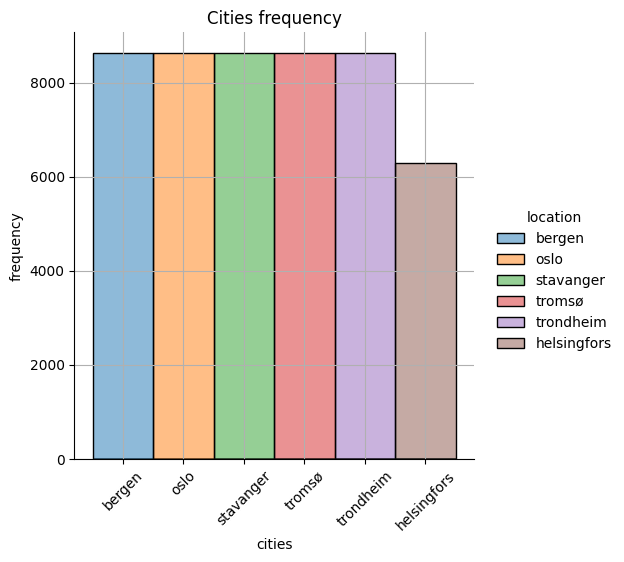

Max frequency 8641 | Min frequency 6289


In [21]:
# distributions
plt.figure(figsize=(10,4))
sns.displot(data=df, x='location', hue='location')
plt.ylabel('frequency')
plt.xlabel('cities')
plt.xticks(rotation=45)
plt.grid()
plt.title('Cities frequency')
plt.show()

print(f'Max frequency {df.location.value_counts().max()} | Min frequency {df.location.value_counts().min()}')


Now we anayze potential **outliers**.

=== GLOBAL OUTLIER SUMMARY ===


,Feature,IQR Lower,IQR Upper,IQR Outliers (N),IQR Outliers (%),Z-Score Outliers (N),Z-Score Outliers (%)
0,consumption,-4.63,11.08,2434,4.92,1283,2.59
1,temperature,-15.65,28.75,36,0.07,17,0.03



[Domain check] Records with consumption <= 0: 32 (0.06%)

=== OUTLIER SUMMARY GROUPED BY LOCATION (IQR METHOD) ===


,location,total_samples,consumption_outliers_n,consumption_outliers_pct,consumption_bounds,temperature_outliers_n,temperature_outliers_pct,temperature_bounds
0,bergen,8641,0,0.0,"[-2.4, 6.2]",39,0.45,"[-10.5, 25.8]"
1,helsingfors,6289,1151,18.3,"[5.8, 6.9]",0,0.00,"[-18.2, 29.5]"
2,oslo,8641,0,0.0,"[-10.7, 24.7]",0,0.00,"[-19.0, 34.1]"
3,stavanger,8641,0,0.0,"[-4.6, 11.4]",19,0.22,"[-8.3, 25.3]"
4,tromsø,8641,0,0.0,"[-0.7, 3.4]",24,0.28,"[-20.9, 27.9]"
5,trondheim,8641,0,0.0,"[-1.9, 6.5]",34,0.39,"[-14.7, 27.4]"


C:\Users\manue\AppData\Local\Temp\ipykernel_21956\3226026017.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='location', y='consumption', ax=axes[0, 0], palette='Blues_r')
C:\Users\manue\AppData\Local\Temp\ipykernel_21956\3226026017.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='location', y='temperature', ax=axes[0, 1], palette='coolwarm')


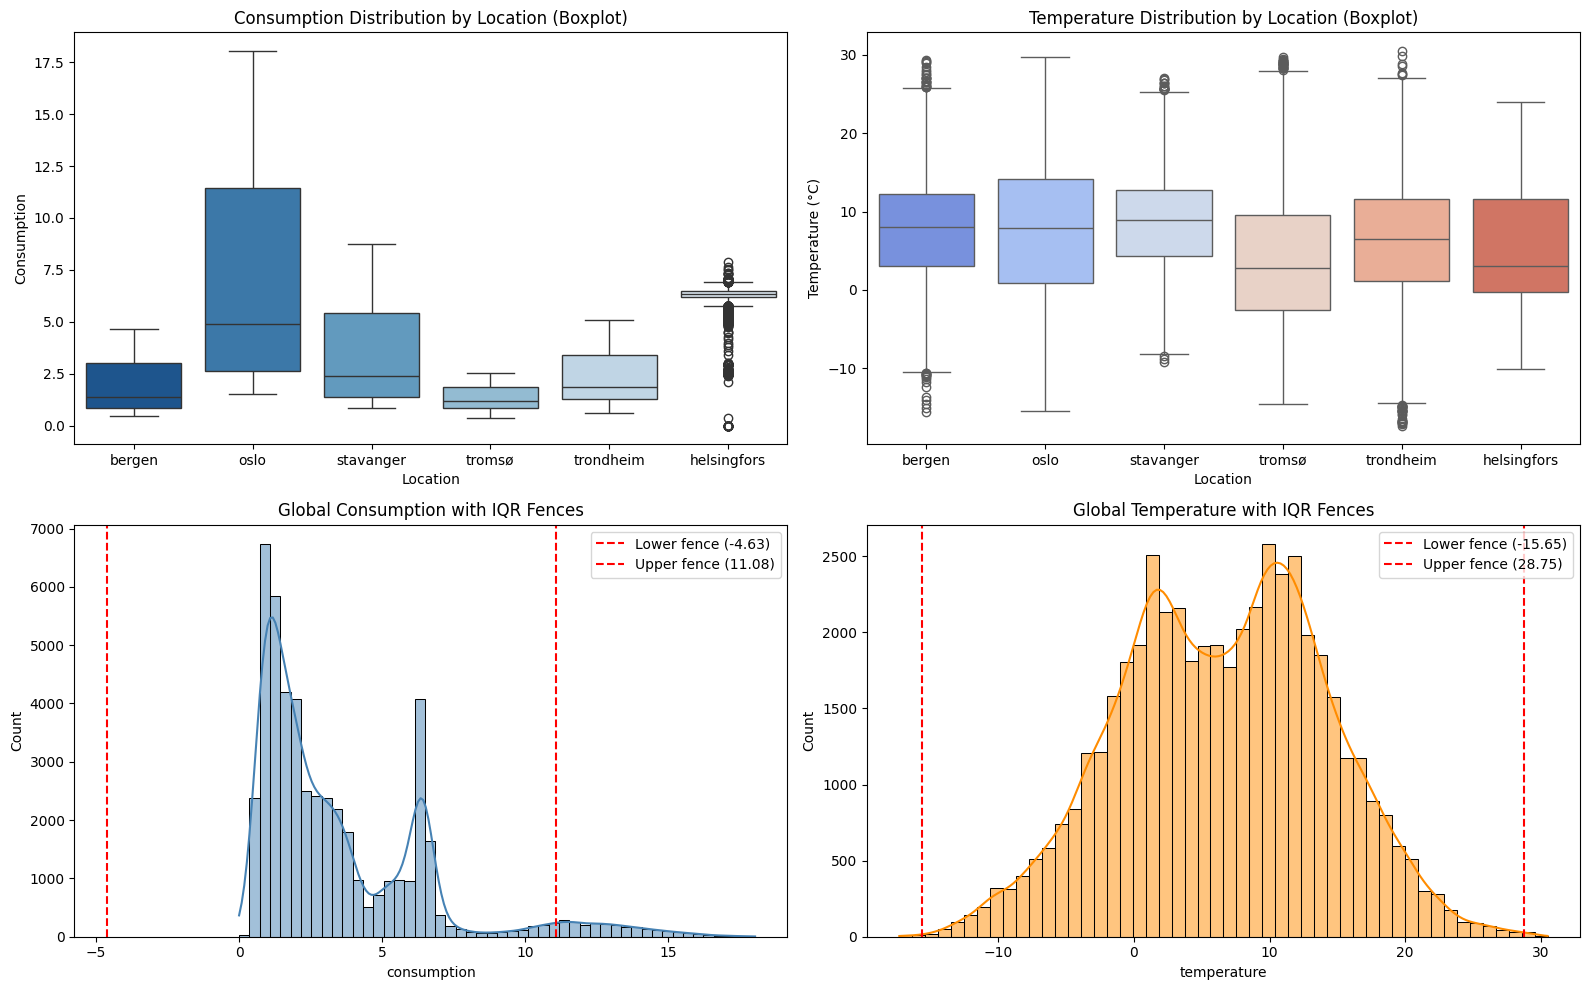

=== TOP 5 HIGHEST CONSUMPTION RECORDS ===


,location,consumption,temperature
time,,,
2022-12-24 15:00:00,oslo,18.045011,-11.0
2023-01-22 16:00:00,oslo,18.031449,-10.1
2023-01-22 17:00:00,oslo,18.025397,-10.1
2023-01-22 18:00:00,oslo,17.869247,-10.2
2023-01-03 16:00:00,oslo,17.865679,-12.1



=== TOP 6 EXTREME TEMPERATURE RECORDS (COLDEST & WARMEST) ===


,location,consumption,temperature
time,,,
2022-12-13 16:00:00,trondheim,4.786505,-17.299999
2022-12-13 11:00:00,trondheim,4.215958,-17.100000
2022-12-13 13:00:00,trondheim,4.280036,-17.000000
2022-06-25 12:00:00,trondheim,0.860169,30.500000
2022-06-25 11:00:00,trondheim,0.851429,29.900000
2022-06-25 13:00:00,oslo,2.318009,29.799999


In [22]:
# ==============================================================================
# OUTLIER DETECTION ANALYSIS (GLOBAL & PER-LOCATION)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_cols = ['consumption', 'temperature']

# ------------------------------------------------------------------------------
# 1. IQR & Z-SCORE FUNCTIONS
# ------------------------------------------------------------------------------
def detect_iqr_outliers(series, factor=1.5):
    """Detect outliers using the Interquartile Range (IQR) rule."""
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - factor * iqr
    upper_bound = q75 + factor * iqr
    is_outlier = (series < lower_bound) | (series > upper_bound)
    return is_outlier, lower_bound, upper_bound

def detect_zscore_outliers(series, threshold=3.0):
    """Detect outliers using standard Z-score (|z| > threshold)."""
    std = series.std()
    if std == 0 or np.isnan(std):
        return pd.Series(False, index=series.index)
    z_scores = (series - series.mean()) / std
    return z_scores.abs() > threshold

# ------------------------------------------------------------------------------
# 2. GLOBAL OUTLIER SUMMARY
# ------------------------------------------------------------------------------
print("=== GLOBAL OUTLIER SUMMARY ===")
global_summary = []
for col in target_cols:
    iqr_mask, lower, upper = detect_iqr_outliers(df[col])
    z_mask = detect_zscore_outliers(df[col])
    global_summary.append({
        'Feature': col,
        'IQR Lower': round(lower, 2),
        'IQR Upper': round(upper, 2),
        'IQR Outliers (N)': iqr_mask.sum(),
        'IQR Outliers (%)': round(iqr_mask.mean() * 100, 2),
        'Z-Score Outliers (N)': z_mask.sum(),
        'Z-Score Outliers (%)': round(z_mask.mean() * 100, 2),
    })

global_summary_df = pd.DataFrame(global_summary)
display(global_summary_df)

# Check for domain-specific invalid values (e.g., non-positive consumption)
zero_consumption = (df['consumption'] <= 0).sum()
print(f"\n[Domain check] Records with consumption <= 0: {zero_consumption} ({zero_consumption / len(df) * 100:.2f}%)")

# ------------------------------------------------------------------------------
# 3. GROUPED OUTLIER DETECTION (BY LOCATION)
# ------------------------------------------------------------------------------
# Consumption scales and temperatures differ across cities, so location-wise detection is crucial.
print("\n=== OUTLIER SUMMARY GROUPED BY LOCATION (IQR METHOD) ===")
location_outlier_records = []

for loc, group in df.groupby('location'):
    row = {'location': loc, 'total_samples': len(group)}
    for col in target_cols:
        iqr_mask, lower, upper = detect_iqr_outliers(group[col])
        row[f'{col}_outliers_n'] = iqr_mask.sum()
        row[f'{col}_outliers_pct'] = round(iqr_mask.mean() * 100, 2)
        row[f'{col}_bounds'] = f"[{lower:.1f}, {upper:.1f}]"
    location_outlier_records.append(row)

loc_summary_df = pd.DataFrame(location_outlier_records)
display(loc_summary_df)

# ------------------------------------------------------------------------------
# 4. VISUAL DIAGNOSTICS: BOXPLOTS AND DISTRIBUTIONS
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Boxplot of consumption by location
sns.boxplot(data=df, x='location', y='consumption', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Consumption Distribution by Location (Boxplot)')
axes[0, 0].set_xlabel('Location')
axes[0, 0].set_ylabel('Consumption')

# Boxplot of temperature by location
sns.boxplot(data=df, x='location', y='temperature', ax=axes[0, 1], palette='coolwarm')
axes[0, 1].set_title('Temperature Distribution by Location (Boxplot)')
axes[0, 1].set_xlabel('Location')
axes[0, 1].set_ylabel('Temperature (°C)')

# Overall histogram with IQR fences for consumption
sns.histplot(df['consumption'], kde=True, ax=axes[1, 0], color='steelblue', bins=50)
_, c_low, c_up = detect_iqr_outliers(df['consumption'])
axes[1, 0].axvline(c_low, color='red', linestyle='--', label=f'Lower fence ({c_low:.2f})')
axes[1, 0].axvline(c_up, color='red', linestyle='--', label=f'Upper fence ({c_up:.2f})')
axes[1, 0].set_title('Global Consumption with IQR Fences')
axes[1, 0].legend()

# Overall histogram with IQR fences for temperature
sns.histplot(df['temperature'], kde=True, ax=axes[1, 1], color='darkorange', bins=50)
_, t_low, t_up = detect_iqr_outliers(df['temperature'])
axes[1, 1].axvline(t_low, color='red', linestyle='--', label=f'Lower fence ({t_low:.2f})')
axes[1, 1].axvline(t_up, color='red', linestyle='--', label=f'Upper fence ({t_up:.2f})')
axes[1, 1].set_title('Global Temperature with IQR Fences')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. SAMPLE INSPECTION: TOP EXTREME OUTLIERS
# ------------------------------------------------------------------------------
print("=== TOP 5 HIGHEST CONSUMPTION RECORDS ===")
display(df.nlargest(5, 'consumption'))

print("\n=== TOP 6 EXTREME TEMPERATURE RECORDS (COLDEST & WARMEST) ===")
display(pd.concat([df.nsmallest(3, 'temperature'), df.nlargest(3, 'temperature')]))

### Outlier Analysis & Data Quality Assessment

Based on the statistical detection (IQR and Z-score) and domain-specific checks, we conclude that **no natural consumption or temperature extremes should be trimmed or removed**, with the exception of an initial sensor startup artifact in **Helsingfors**:

1. **Oslo High Consumption (~18 MW)**:
   - While flagged as a statistical outlier globally (~4.9% of total rows), per-location IQR analysis reveals **0.0% outliers for Oslo**. 
   - The highest peaks occur on **Christmas Eve (2022-12-24 15:00)** and during freezing January days (**-10 °C to -12 °C**). In Norway, space heating is predominantly electric; these peaks reflect genuine, physics-driven surges in residential and commercial demand. Removing them would artificially truncate peak-load risk and distort imbalance cost evaluations.

2. **Extreme Temperatures (-17.3 °C to +30.5 °C)**:
   - The extreme minimum of **-17.3 °C** occurred in Trondheim during a severe cold front on December 13, 2022.
   - The maximum of **+30.5 °C** occurred during the documented Scandinavian heatwave of late June 2022 (June 25, 2022).
   - Both are physically valid, verified meteorological records. Retaining them is essential for models to learn weather-elastic demand sensitivity.

3. **Helsingfors Narrow IQR Variance**:
   - The 18.3% of points flagged as outliers in Helsingfors is a statistical artifact caused by an exceptionally narrow interquartile range ($\text{IQR} = 0.28\text{ MW}$ around a baseline of $\sim 6.35\text{ MW}$). The points outside the bounds represent normal seasonal heating/cooling cycles rather than data corruption.

4. **Actionable Anomaly — The 32 Initial Zeros in Helsingfors**:
   - Exactly 32 consecutive observations in `helsingfors` report `consumption == 0.0 MW`, running continuously from `2022-07-14 21:00:00` to `2022-07-16 04:00:00`.
   - This corresponds precisely to the very start of the Helsingfors recording series, indicating a meter initialization/telemetry latency before active data streaming began.
   - **Remediation**: Rather than dropping random rows (which would introduce time-series gaps and break autoregressive lag structures), we trim the start date for Helsingfors to **2022-07-16 05:00:00**, ensuring complete hourly continuity (`freq='h'`) across all locations.

In [23]:
# ==============================================================================
# REMEDIATION: TRIM UNMETERED INITIAL STARTUP FOR HELSINGFORS
# ==============================================================================
# The first 32 hours of Helsingfors (2022-07-14 21:00 to 2022-07-16 04:00) 
# contain 0.0 MW artifacts from sensor commissioning. We trim the series to begin
# at 2022-07-16 05:00:00, preserving complete hourly continuity.

initial_len = len(df)

# Filter out the initial 32 unmetered hours of Helsingfors
helsinki_startup_mask = (df['location'] == 'helsingfors') & (df.index < '2022-07-16 05:00:00')
df = df[~helsinki_startup_mask]

# Verification checks
removed_count = initial_len - len(df)
remaining_zeros = (df['consumption'] <= 0).sum()

h_series = df[df['location'] == 'helsingfors']
expected_h_range = pd.date_range(start=h_series.index.min(), end=h_series.index.max(), freq='h')
missing_h_hours = len(expected_h_range.difference(h_series.index))

print(f"Rows removed: {removed_count} (expected: 32)")
print(f"Remaining records with consumption <= 0: {remaining_zeros}")
print(f"New Helsingfors start date: {h_series.index.min()}")
print(f"Missing hourly timestamps in Helsingfors: {missing_h_hours}")
print(f"Updated DataFrame shape: {df.shape}")

Rows removed: 32 (expected: 32)
Remaining records with consumption <= 0: 0
New Helsingfors start date: 2022-07-16 05:00:00
Missing hourly timestamps in Helsingfors: 0
Updated DataFrame shape: (49462, 3)


Now let's analyze the **Consumption:** average hourly electricity consumption served by the retailer, measured in MW.

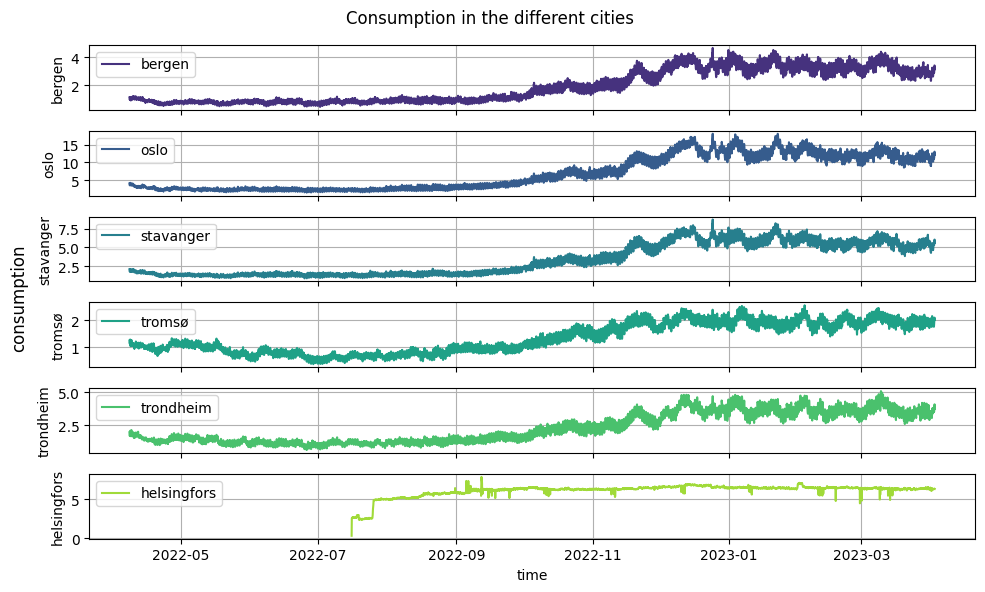

In [24]:
# analysing the consumption in the different cities timeseries
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))

fig, ax = plt.subplots(6, 1, figsize=(10, 6), sharex=True)

for i, city in enumerate(cities):
    sns.lineplot(
        df[df['location'] == city], 
        x='time', 
        y='consumption', 
        ax=ax[i], 
        label=city, 
        color=palette[i] 
    )
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

plt.xlabel('time')
fig.supylabel('consumption')
fig.suptitle('Consumption in the different cities') 
plt.tight_layout()
plt.show()

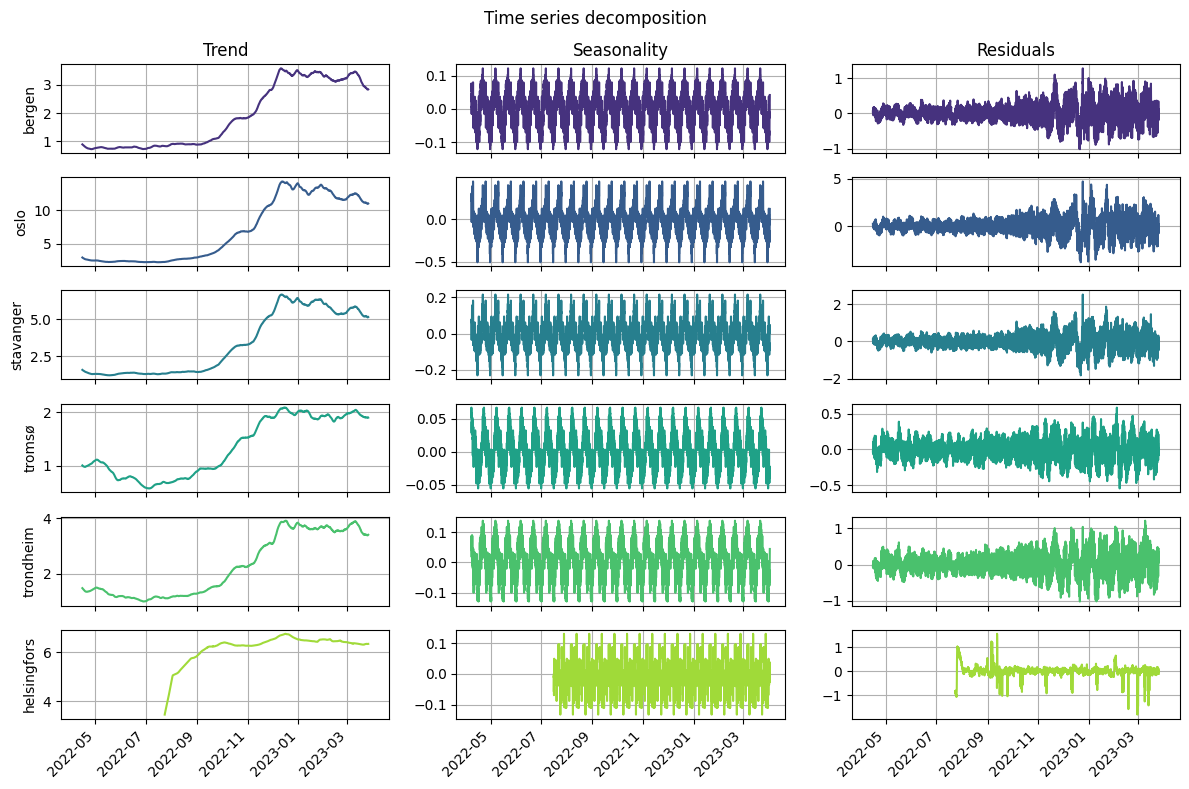

In [25]:
# Consumption time sereis decomposiont (for each city)

# get the city name
cities = df['location'].unique()

# color palette
palette = sns.color_palette('viridis', len(cities))

# creating a grid 6x3
#   6: cities
#   3: components
fig, ax = plt.subplots(6,3, figsize=(12, 8), sharex=True)

for i, city in enumerate(cities):
    
    # get city data
    df_city = df[df['location'] == city].copy()
    
    # time series decomposiotion
    decomposition = seasonal_decompose(df_city['consumption'], model='additive', period=365)
    trend = decomposition.trend
    seasonal = decomposition.seasonal
    resid = decomposition.resid
    
    # getting city color from the palette
    color = palette[i]
    
    # plot of the 3 components
    #   trend
    ax[i, 0].plot(trend.index, trend, color=color)
    ax[i, 0].set_ylabel(f'{city}')
    ax[i, 0].grid()
    # sesonality
    ax[i, 1].plot(seasonal.index, seasonal, color=color)
    ax[i, 1].grid()
    # residuals
    ax[i, 2].plot(resid.index, resid, color=color)
    ax[i, 2].grid()

# titles
ax[0, 0].set_title('Trend')
ax[0, 1].set_title('Seasonality')
ax[0, 2].set_title('Residuals')

fig.autofmt_xdate(rotation=45, ha='right')

fig.suptitle('Time series decomposition')
plt.tight_layout()
plt.show()

### Consumption VS Tempearature

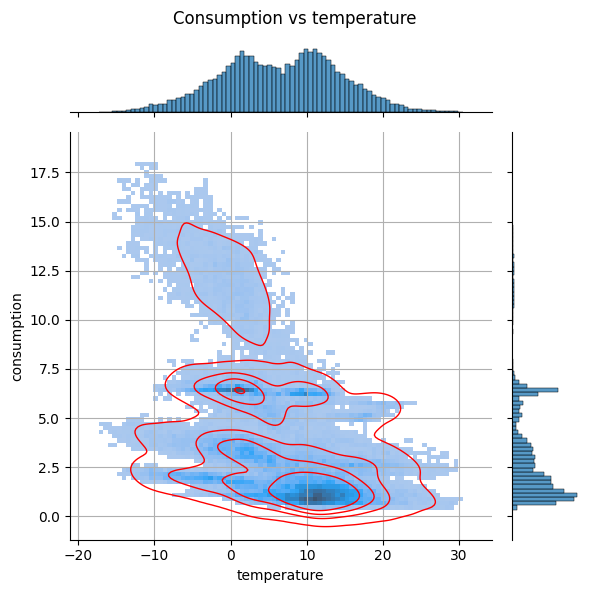

In [26]:
sns.jointplot(data=df, x='temperature', y='consumption', kind='hist')
sns.kdeplot(data=df, x='temperature', y='consumption', levels=5, color="red", linewidths=1)
plt.suptitle('Consumption vs temperature')
plt.grid()
plt.tight_layout()
plt.show()

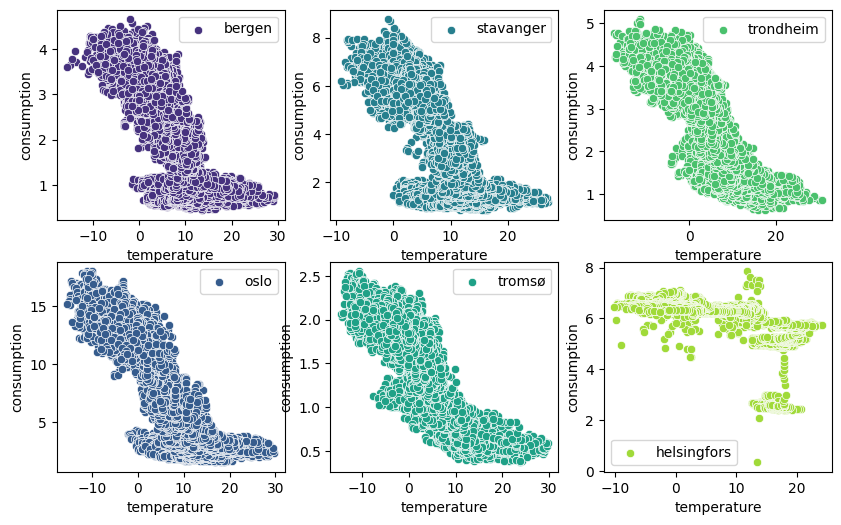

In [27]:
# get the city name
cities = df['location'].unique()
# color palette
palette = sns.color_palette('viridis', len(cities))
# plotting
fig, ax = plt.subplots(2,3, figsize=(10,6))
count = 0
j = 0
i = 0
for a, city in enumerate(cities):
    sns.scatterplot(data=df[df['location']==city], x='temperature',
                        y='consumption', color=palette[a], ax=ax[i,j],
                        label=city)
    count += 1
    i += 1
    if count == 2 and i == 2:
        j += 1
        count = 0
        i = 0


In [28]:
# enconding the cities names
df['location'] = df['location'].astype('category')
corr_mat = df.groupby('location', observed=True)[['consumption', 'temperature']].corr().xs('temperature', level=1)['consumption']
corr_mat

location
bergen        -0.781353
helsingfors   -0.600614
oslo          -0.861854
stavanger     -0.781747
tromsø        -0.863436
trondheim     -0.837779
Name: consumption, dtype: float64

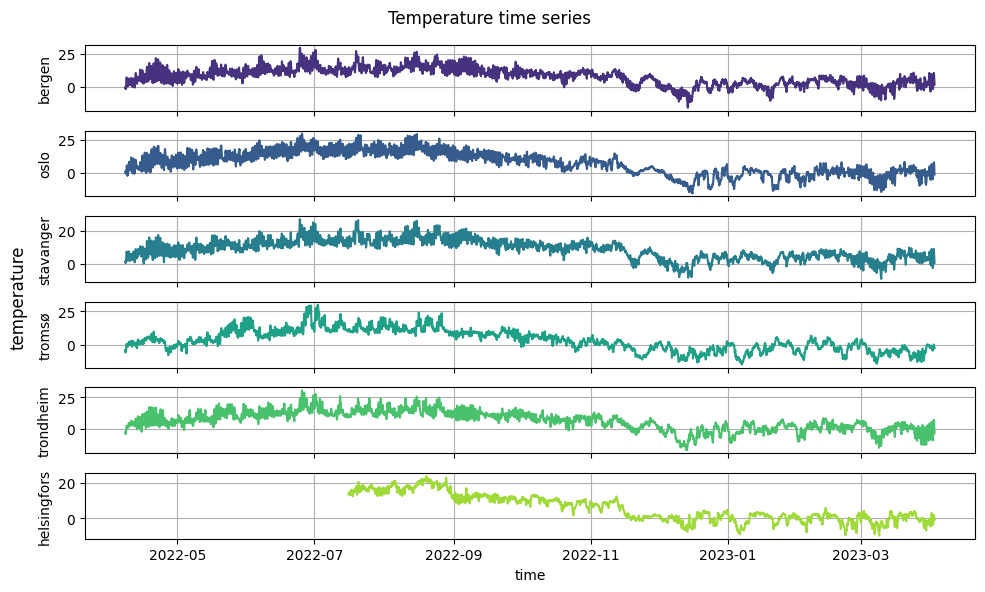

In [29]:
fig, ax = plt.subplots(6,1, figsize=(10,6), sharex=True)
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))
for i, city in enumerate(cities):
    sns.lineplot(data=df[df['location']==city], x='time', y='temperature', color=palette[i], ax=ax[i])
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

fig.supylabel('temperature')
fig.suptitle('Temperature time series')
plt.tight_layout()
plt.show()

### Model proposal

1. Baseline: same hour at D-7.
2. LightGBM global on normalized target:
    - features: houre, week day, weekends, weather forecast, hourly lags 120/144/168/336h, rolling average at lag ≥ 120h. 
        - Avoid month; 
        - Location as category (no LabelEncoder).
3. Ridge/GAM for area.


First: define the function for the metrics

In [30]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Global internal cache for Nord Pool prices to avoid repeated disk reads
_NORDPOOL_CACHE = None


def _load_internal_prices(prices_path: str = "nordpool_prices.csv"):
    """Internal helper to load and cache Nord Pool hourly prices."""
    global _NORDPOOL_CACHE
    if _NORDPOOL_CACHE is None:
        if not os.path.exists(prices_path):
            raise FileNotFoundError(
                f"Missing required prices file: '{prices_path}'. "
                "Ensure nordpool_prices.csv is in the working directory."
            )
        pdf = pd.read_csv(prices_path)
        pdf["time"] = pd.to_datetime(pdf["time"], utc=True)
        if "spot_price_nok_mwh" not in pdf.columns:
            # Convert EUR/MWh to NOK/MWh using average historical exchange rate (10.5 NOK/EUR)
            pdf["spot_price_nok_mwh"] = pdf["spot_price_eur_mwh"] * 10.5
        _NORDPOOL_CACHE = pdf[["time", "location", "spot_price_nok_mwh"]].copy()
    return _NORDPOOL_CACHE


def compute_forecast_metrics(
    y_true: pd.Series | np.ndarray,
    y_pred: pd.Series | np.ndarray,
    timestamps: pd.Series | pd.DatetimeIndex | None = None,
    locations: pd.Series | np.ndarray | str | None = None,
    y_baseline: pd.Series | np.ndarray | None = None,
    contract_fee: float = 100_000.0,
    min_consumption_lag_hours: int = 168,
    pipeline_runtime_sec: float = 12.0,
    sla_max_runtime_sec: float = 1800.0,
    trust_tolerance_ratio: float = 0.15,
    prices_csv_path: str = "nordpool_prices.csv",
) -> dict:
    """Black-box 4-Tier evaluation function for Electricity Consumption Forecasting.

    Nord Pool prices are automatically loaded and matched internally via
    timestamps and locations.
    """
    # -------------------------------------------------------------------------
    # 0. Data Extraction & Internal Alignment
    # -------------------------------------------------------------------------
    # Extract timestamps from Series index if not provided explicitly
    if timestamps is None and isinstance(y_true, pd.Series):
        timestamps = y_true.index

    # Build evaluation frame
    eval_df = pd.DataFrame(
        {
            "y_t": np.asarray(y_true, dtype=float),
            "y_p": np.asarray(y_pred, dtype=float),
        }
    )

    if y_baseline is not None:
        eval_df["y_b"] = np.asarray(y_baseline, dtype=float)

    if timestamps is not None:
        eval_df["time"] = pd.to_datetime(timestamps, utc=True)

    if locations is not None:
        if isinstance(locations, str):
            eval_df["location"] = locations
        else:
            eval_df["location"] = np.asarray(locations)

    # Filter NaN values across inputs
    cols_to_check = (
        ["y_t", "y_p", "y_b"] if y_baseline is not None else ["y_t", "y_p"]
    )
    eval_df = eval_df.dropna(subset=cols_to_check).copy()

    if len(eval_df) == 0:
        raise ValueError("No valid overlapping observations found.")

    # -------------------------------------------------------------------------
    # Black-box Price Loading & Merge
    # -------------------------------------------------------------------------
    if "time" in eval_df.columns and "location" in eval_df.columns:
        nordpool_df = _load_internal_prices(prices_csv_path)
        eval_df = pd.merge(
            eval_df, nordpool_df, on=["time", "location"], how="left"
        )
        # Fallback to mean price if any timestamp is unmapped
        eval_df["spot_price_nok_mwh"] = eval_df["spot_price_nok_mwh"].fillna(
            nordpool_df["spot_price_nok_mwh"].mean()
        )
        hourly_prices = eval_df["spot_price_nok_mwh"].values
    else:
        # Fallback if timestamps/locations are omitted: use average historical market price (~1500 NOK/MWh)
        hourly_prices = np.full(len(eval_df), 1500.0)

    y_t = eval_df["y_t"].values
    y_p = eval_df["y_p"].values
    y_b = eval_df["y_b"].values if "y_b" in eval_df.columns else None

    # -------------------------------------------------------------------------
    # TIER 1: Technical & Statistical Modeling Metrics
    # -------------------------------------------------------------------------
    errors = y_p - y_t
    abs_errors = np.abs(errors)
    sum_actual = np.sum(y_t)

    mae = float(np.mean(abs_errors))
    rmse = float(np.sqrt(np.mean(errors**2)))
    wape = float((np.sum(abs_errors) / sum_actual) * 100) if sum_actual > 0 else np.nan
    nmbe = float((np.sum(errors) / sum_actual) * 100) if sum_actual > 0 else np.nan

    if y_b is not None:
        mae_base = float(np.mean(np.abs(y_b - y_t)))
        skill_score = (
            float((1.0 - (mae / mae_base)) * 100) if mae_base > 0 else 0.0
        )
    else:
        skill_score = 0.0

    # -------------------------------------------------------------------------
    # TIER 2: Business & Financial Value KPIs (Real Nord Pool Settlement)
    # -------------------------------------------------------------------------
    # 1 MW over 1 hour = 1 MWh
    total_imbalance_mwh = float(np.sum(abs_errors) * 1.0)
    real_imbalance_cost_nok = float(np.sum(abs_errors * hourly_prices))

    if y_b is not None:
        base_imbalance_mwh = float(np.sum(np.abs(y_b - y_t)) * 1.0)
        avoided_mwh = float(base_imbalance_mwh - total_imbalance_mwh)
        imbalance_reduction_pct = (
            float((avoided_mwh / base_imbalance_mwh) * 100)
            if base_imbalance_mwh > 0
            else 0.0
        )

        base_imbalance_cost_nok = float(np.sum(np.abs(y_b - y_t) * hourly_prices))
        avoided_cost_nok = float(
            base_imbalance_cost_nok - real_imbalance_cost_nok
        )
    else:
        avoided_mwh = 0.0
        imbalance_reduction_pct = 0.0
        avoided_cost_nok = 0.0

    # -------------------------------------------------------------------------
    # TIER 3: Operational, Latency & MLOps SLA
    # -------------------------------------------------------------------------
    leakage_passed = min_consumption_lag_hours >= 120
    timeliness_passed = pipeline_runtime_sec <= sla_max_runtime_sec

    # ---------------------------------------------------------
    # TIER 4: Client Relationship & Trust
    # ---------------------------------------------------------
    service_roi_pct = (
        float(((avoided_cost_nok - contract_fee) / contract_fee) * 100)
        if (contract_fee > 0 and y_b is not None)
        else np.nan
    )
    trust_reliability_pct = float(
        np.mean(abs_errors / np.where(y_t == 0, np.nan, y_t) <= trust_tolerance_ratio)
        * 100
    )
    p95_imbalance_mw = float(np.percentile(abs_errors, 95))

    return {
        # Tier 1
        "T1: MAE [MW]": mae,
        "T1: RMSE [MW]": rmse,
        "T1: WAPE [%]": wape,
        "T1: NMBE [%]": nmbe,
        "T1: Outperformance [%]": skill_score,
        # Tier 2
        "T2: Total Imbalance [MWh]": total_imbalance_mwh,
        "T2: Avoided Imbalance [MWh]": avoided_mwh,
        "T2: Imbalance Cost [NOK]": real_imbalance_cost_nok,
        "T2: Avoided Cost [NOK]": avoided_cost_nok,
        # Tier 3
        "T3: Leakage (>=120h)": "PASS"
        if leakage_passed
        else "FAIL (Data Leakage)",
        "T3: Timeliness (SLA)": "PASS" if timeliness_passed else "FAIL (Late)",
        # Tier 4
        "T4: Service ROI [%]": service_roi_pct,
        f"T4: Trust (Err <{trust_tolerance_ratio*100:.0f}%) [%]": trust_reliability_pct,
        "T4: P95 Imbalance [MW]": p95_imbalance_mw,
    }


def evaluate_forecast_by_location(
    data: pd.DataFrame,
    pred_col: str,
    target_col: str = "consumption",
    baseline_col: str | None = "baseline_pred_7d",
    location_col: str = "location",
    contract_fee_per_city: float = 100_000.0,
    min_lag_hours: int = 120,
) -> pd.DataFrame:
    """Helper to evaluate across all locations using the black-box metric function."""
    results = []

    # Ensure time is accessible
    time_series = data.index if isinstance(data.index, pd.DatetimeIndex) else data["time"]

    # Per-city evaluation
    for loc, group in data.groupby(location_col, observed=False):
        g_time = (
            group.index
            if isinstance(group.index, pd.DatetimeIndex)
            else group["time"]
        )
        metrics = compute_forecast_metrics(
            y_true=group[target_col],
            y_pred=group[pred_col],
            timestamps=g_time,
            locations=loc,
            y_baseline=group[baseline_col] if baseline_col else None,
            contract_fee=contract_fee_per_city,
            min_consumption_lag_hours=min_lag_hours,
        )
        metrics[location_col] = str(loc)
        results.append(metrics)

    # Overall portfolio evaluation
    overall_metrics = compute_forecast_metrics(
        y_true=data[target_col],
        y_pred=data[pred_col],
        timestamps=time_series,
        locations=data[location_col],
        y_baseline=data[baseline_col] if baseline_col else None,
        contract_fee=contract_fee_per_city * len(results),
        min_consumption_lag_hours=min_lag_hours,
    )
    overall_metrics[location_col] = "OVERALL"
    results.append(overall_metrics)

    return pd.DataFrame(results).set_index(location_col)

=== 4-TIER BASELINE EVALUATION (Black-Box Nord Pool Integration) ===


,T1: MAE [MW],T1: RMSE [MW],T1: WAPE [%],T1: NMBE [%],T1: Outperformance [%],T2: Total Imbalance [MWh],T2: Avoided Imbalance [MWh],T2: Imbalance Cost [NOK],T2: Avoided Cost [NOK],T3: Leakage (>=120h),T3: Timeliness (SLA),T4: Service ROI [%],T4: Trust (Err <15%) [%],T4: P95 Imbalance [MW]
location,,,,,,,,,,,,,,
bergen,0.24,0.35,12.85,-1.94,0.0,2062.12,0.0,3510235.51,0.0,PASS,PASS,-100.0,64.86,0.78
helsingfors,0.20,0.46,3.25,-1.68,0.0,1227.43,0.0,2103645.84,0.0,PASS,PASS,-100.0,96.11,0.60
oslo,0.86,1.35,12.38,-2.28,0.0,7284.01,0.0,12372385.08,0.0,PASS,PASS,-100.0,72.62,3.32
stavanger,0.40,0.60,12.01,-2.16,0.0,3394.09,0.0,5996960.17,0.0,PASS,PASS,-100.0,72.24,1.39
tromsø,0.14,0.18,10.58,-1.24,0.0,1206.38,0.0,478929.44,0.0,PASS,PASS,-100.0,71.18,0.37
trondheim,0.29,0.39,12.62,-1.56,0.0,2449.15,0.0,1931926.50,0.0,PASS,PASS,-100.0,66.07,0.88
OVERALL,0.36,0.68,10.26,-1.95,0.0,17623.18,0.0,26394082.55,0.0,PASS,PASS,-100.0,72.75,1.42


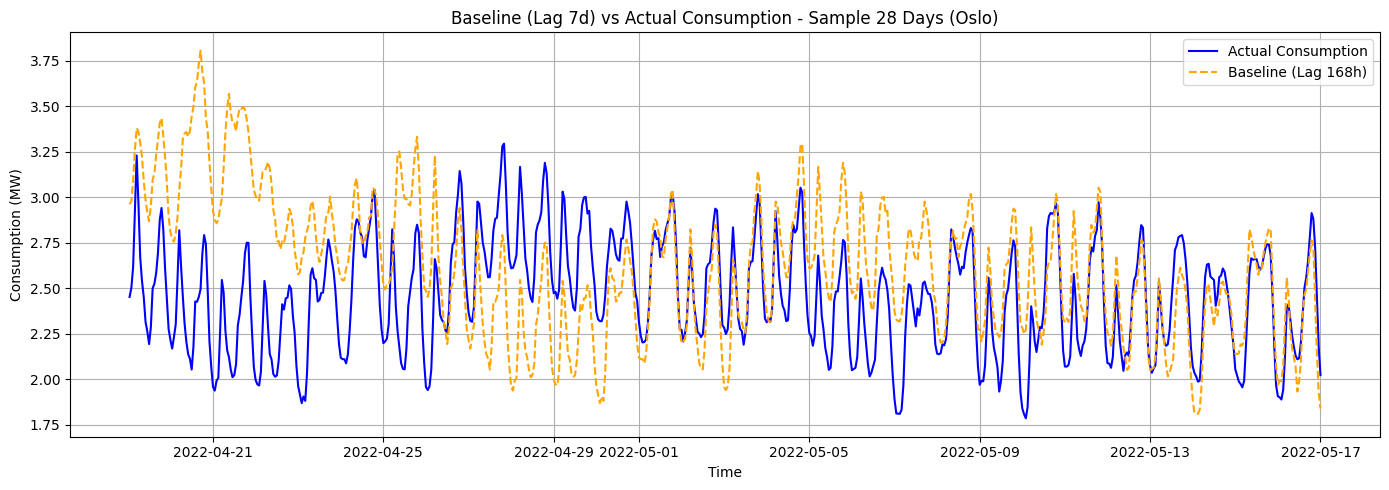

In [31]:
# ==============================================================================
# EXECUTION DEMO: Baseline Evaluation
# ==============================================================================
# 1. Generate 7-day Naïve Baseline
df = df.sort_index()
df["baseline_pred_7d"] = df.groupby("location", observed=False)[
    "consumption"
].shift(168)
eval_df = df.dropna(subset=["baseline_pred_7d"]).copy()

# 2. Evaluate (Zero manual price handling required by the caller)
baseline_metrics_summary = evaluate_forecast_by_location(
    data=eval_df,
    pred_col="baseline_pred_7d",
    contract_fee_per_city=100_000.0,
)

print("=== 4-TIER BASELINE EVALUATION (Black-Box Nord Pool Integration) ===")
display(baseline_metrics_summary.round(2))

# Graphical visualization on a sample interval (e.g., 2 weeks in Oslo)
sample_city = 'oslo'
n_days = 28
df_sample = eval_df[eval_df['location'] == sample_city].iloc[100:100 + 24 * n_days]

plt.figure(figsize=(14, 5))
plt.plot(df_sample.index, df_sample['consumption'], label='Actual Consumption', color='blue')
plt.plot(df_sample.index, df_sample['baseline_pred_7d'], label='Baseline (Lag 168h)', color='orange', linestyle='--')
plt.title(f'Baseline (Lag 7d) vs Actual Consumption - Sample {n_days} Days ({sample_city.capitalize()})')
plt.xlabel('Time')
plt.ylabel('Consumption (MW)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Note: Outperformance, Avoided Imbalance, Avoided Cost and Service ROI are all metrics that we have to compare with models other than the baseline, since they are calculated w.r.t. the baseline.

Some tricky KPIs:
- ROI is calculated based on avoided costs w.r.t the baseline over the contract fee.
- Trust is how many hours the consumption error (MAE) stays within a certain treshold. The higher, the better for the clients (Stakeholder Trust).
- P95 Imbalance means: in 95% of the hours, the error will be less than this value. Only in critical 5% it will be more than this. It helps the retailer’s risk manager decide how much financial reserve or balancing capacity to keep on hand to cover worst-case scenarios. The lower, the better (usually good if: P95 < 2.5 * MAE)



### Features

In [32]:
# need to have time local time for each area
df.index = df.index.tz_localize('UTC')   
tz = {'helsingfors': 'Europe/Helsinki'}  

parts = []
for loc, g in df.groupby('location'):
    t = g.index.tz_convert(tz.get(loc, 'Europe/Oslo'))
    parts.append(g.assign(hour=t.hour, dow=t.dayofweek, local_date=t.normalize().tz_localize(None)))
df = pd.concat(parts).sort_index()

C:\Users\manue\AppData\Local\Temp\ipykernel_21956\803034288.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for loc, g in df.groupby('location'):


In [34]:
import holidays

cal = {'helsingfors': holidays.Finland(years=[2022, 2023])}
default_cal = holidays.Norway(years=[2022, 2023])

df['is_holiday'] = [
    d in cal.get(loc, default_cal)
    for d, loc in zip(df['local_date'], df['location'])
]

# is_off = holidays or weekends
df['is_off'] = (df['is_holiday'] | (df['dow'] >= 5)).astype(int)
df['day_of_week'] = df['dow']
df= df.drop(columns='dow')

In [35]:
df.head(10)

,location,consumption,temperature,baseline_pred_7d,hour,local_date,is_holiday,is_off,day_of_week
time,,,,,,,,,
2022-04-07 21:00:00+00:00,bergen,1.113325,-0.3,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,stavanger,2.057858,1.3,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,tromsø,1.246582,-3.9,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,trondheim,1.970098,-2.8,NaN,23,2022-04-07,False,0,3
2022-04-07 21:00:00+00:00,oslo,4.092830,1.0,NaN,23,2022-04-07,False,0,3
2022-04-07 22:00:00+00:00,oslo,3.818095,0.4,NaN,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,bergen,1.050327,0.0,NaN,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,stavanger,1.918996,0.8,NaN,0,2022-04-08,False,0,4
2022-04-07 22:00:00+00:00,tromsø,1.180321,-4.3,NaN,0,2022-04-08,False,0,4


In [36]:
df.loc[df['is_holiday'], 'local_date'].drop_duplicates().sort_values().dt.date.tolist()

[datetime.date(2022, 4, 14),
 datetime.date(2022, 4, 15),
 datetime.date(2022, 4, 17),
 datetime.date(2022, 4, 18),
 datetime.date(2022, 5, 1),
 datetime.date(2022, 5, 17),
 datetime.date(2022, 5, 26),
 datetime.date(2022, 6, 5),
 datetime.date(2022, 6, 6),
 datetime.date(2022, 11, 5),
 datetime.date(2022, 12, 6),
 datetime.date(2022, 12, 24),
 datetime.date(2022, 12, 25),
 datetime.date(2022, 12, 26),
 datetime.date(2023, 1, 1),
 datetime.date(2023, 1, 6)]

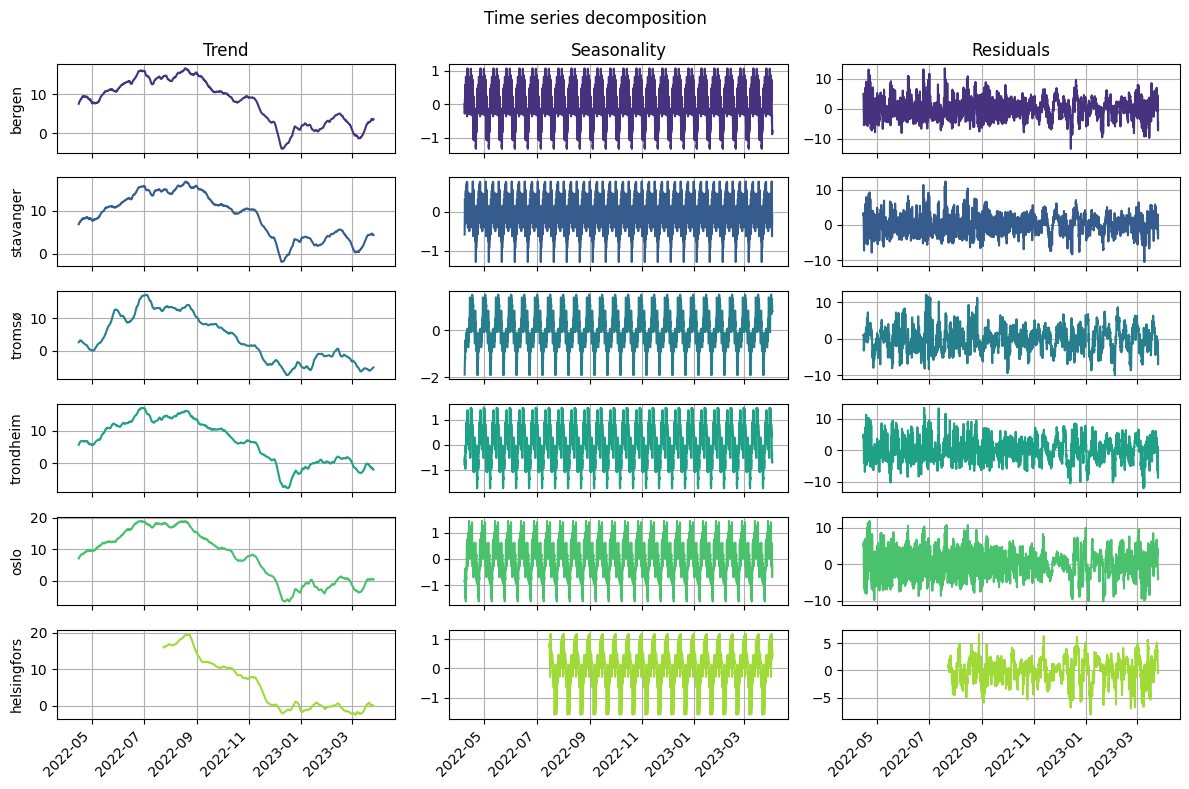

In [37]:
# Consumption time sereis decomposiont (for each city)

# get the city name
cities = df['location'].unique()

# color palette
palette = sns.color_palette('viridis', len(cities))

# creating a grid 6x3
#   6: cities
#   3: components
fig, ax = plt.subplots(6,3, figsize=(12, 8), sharex=True)

for i, city in enumerate(cities):
    
    # get city data
    df_city = df[df['location'] == city].copy()
    
    # time series decomposiotion
    decomposition = seasonal_decompose(df_city['temperature'], model='additive', period=365)
    trend = decomposition.trend
    seasonal = decomposition.seasonal
    resid = decomposition.resid
    
    # getting city color from the palette
    color = palette[i]
    
    # plot of the 3 components
    #   trend
    ax[i, 0].plot(trend.index, trend, color=color)
    ax[i, 0].set_ylabel(f'{city}')
    ax[i, 0].grid()
    # sesonality
    ax[i, 1].plot(seasonal.index, seasonal, color=color)
    ax[i, 1].grid()
    # residuals
    ax[i, 2].plot(resid.index, resid, color=color)
    ax[i, 2].grid()

# titles
ax[0, 0].set_title('Trend')
ax[0, 1].set_title('Seasonality')
ax[0, 2].set_title('Residuals')

fig.autofmt_xdate(rotation=45, ha='right')

fig.suptitle('Time series decomposition')
plt.tight_layout()
plt.show()

In [38]:
df.is_off.value_counts()

is_off
0    34254
1    15208
Name: count, dtype: int64

### Consumption by city: week days vs of days

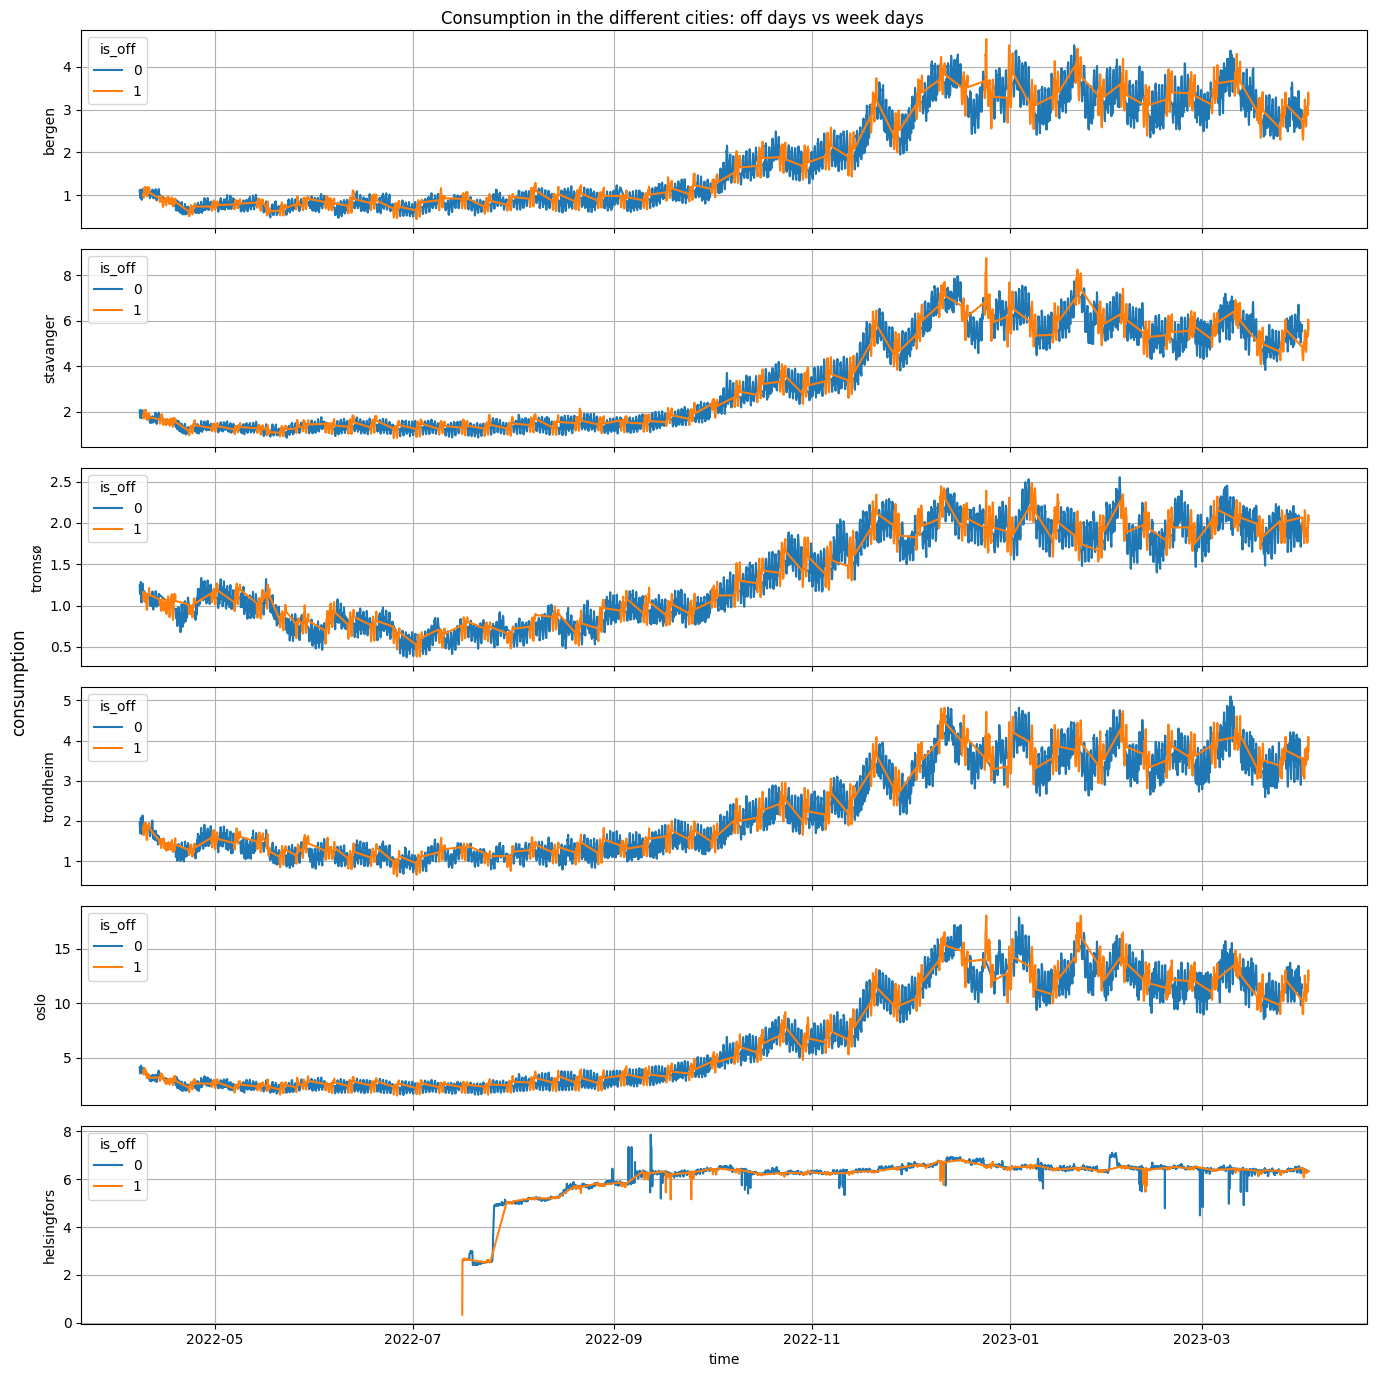

In [39]:
# analysing the consumption in the different cities timeseries
cities = df['location'].unique()
palette = sns.color_palette('viridis', len(cities))

fig, ax = plt.subplots(6, 1, figsize=(14,14), sharex=True)


for i, city in enumerate(cities):
    city_maks = df['location'] == city
    sns.lineplot(
        df[city_maks], 
        x='time', 
        y='consumption', 
        ax=ax[i], 
        hue='is_off',
        color=palette[i] 
    )
    ax[i].grid()
    ax[i].set_ylabel(f'{city}')

plt.xlabel('time')
fig.supylabel('consumption')
fig.suptitle('Consumption in the different cities: off days vs week days') 
plt.tight_layout()
plt.show()

### Consumption trend vs temperature trend